## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()


26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

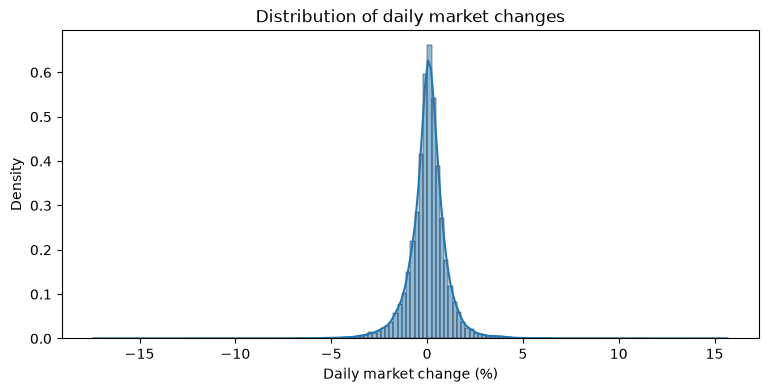

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

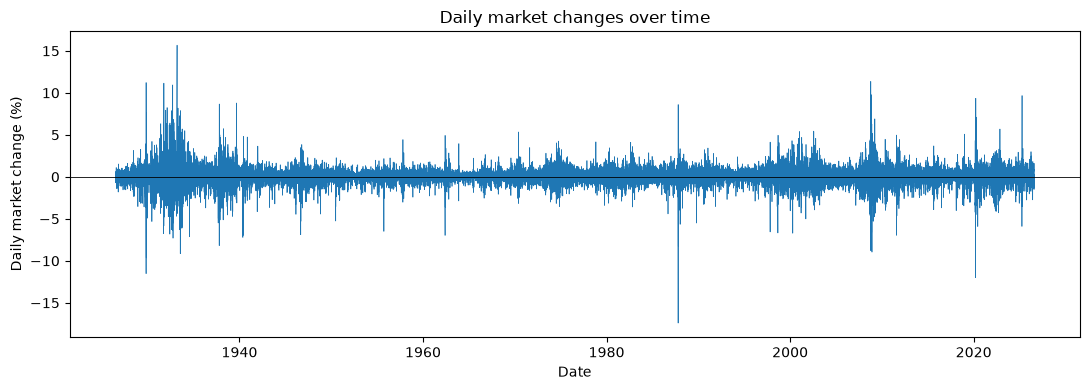

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True,
)

In [5]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

In [6]:
df[["direction_t","direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down / flat
...,...,...
26291,Up,Up
26292,Up,Down / flat
26293,Down / flat,Up
26294,Up,Up


In [7]:
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


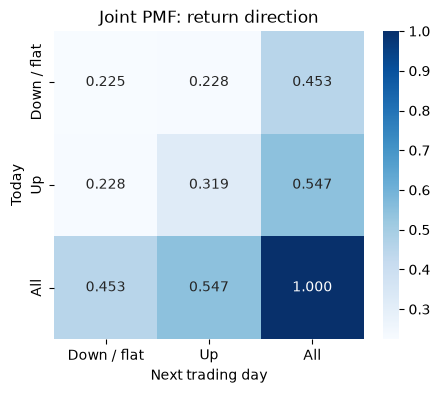

In [8]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [41]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'],normalize = 'index')

pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='index',
            rownames=['Today'], colnames=['Tomorrow'])

Tomorrow,Down / flat,Up
Today,,
Down / flat,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 

<em> Up transitions are more common than down transitions.</em>


- Are you more likely to transition to an Up day from a Down or Up day?

<em> You are more likely to transition from an Up day to an Up day (0.583) than from a Down day to an Up day (0.504).</em>

</div>

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [10]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1,1, np.inf], labels = return_categories)


In [11]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [12]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [13]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)

<em>

Small gain: 9785 days

Small loss: 7452 days

Near 0: 3441 days

Big gain: 2859 days

Big loss: 2759

</em>
- Which are the most or least common?
  
<em>

Small gains are the most common. Big losses are the least common.

</em>
  </div>

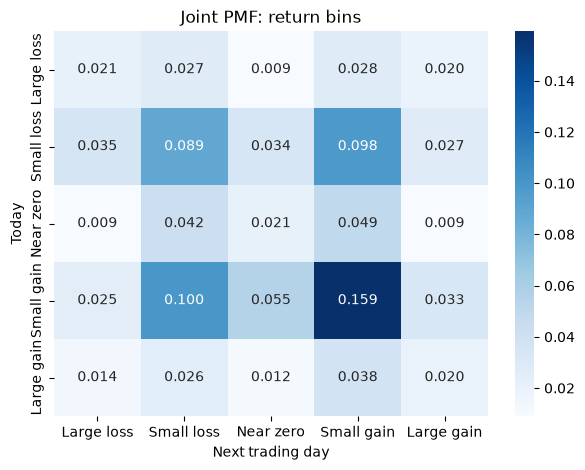

In [14]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

<em>

Small gains to small gains is the most likely transition.  Overall, small losses and small gains transitioning to small losses and small gains are the most likely transitions.


</em>

</div>

In [15]:
#conditional PMF 
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


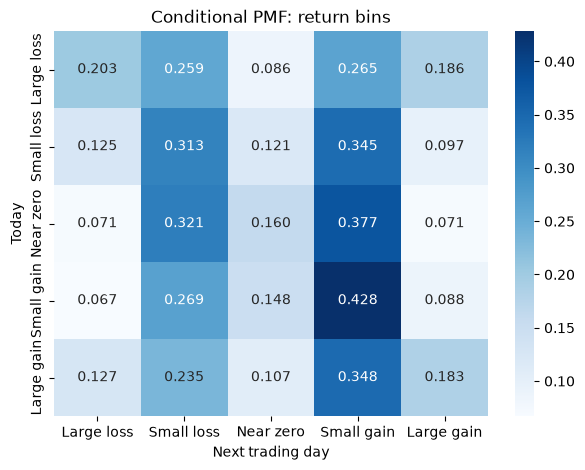

In [16]:
#joint PMF with marginals
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1'], normalize="index"),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
<em>

Today-Large loss: Small gains, small losses

Today-Small loss:Small gains, small losses

Today-Near zero: Small gains, small losses

Today-Small gain: Small gains, small losses

Today-Large gain: Small gains, small losses



</em>

- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 

<em>


A uniform mass function with probability of .2 over each transition would mean each outcome is equally likely.  We do not have a uniform mass function here.  The small losses, small gains and near zero rows are the farthest rows from uniform ranging from 0.067 to 0.428. The large losses and large gains rows are more similar to uniform; large losses being the flattest ranging from 0.086 to 0.265.  



Overall, small gains and losses are more likely than large gains, large losses and near zero returns. Additionally, we do see in the PMF, that the small losses and small gains are always the most likely tomorrow regardless of what today was. Small gains are also more likely across every today condition than small losses (in some today conditions the magnitude of the difference is larger than in others).  We see minor fluctuations of the magnitude of the probabilities across different today values. 

</em>

- Is it relatively easy or difficult to predict the next state?


<em>

The next state is most likely to be a small gain or loss regardless of the current state; however, today is associated with slight variation in the magnitude of the probability for small and large gains and losses tomorrow. I would say that it is not difficult to narrow down to two options to predict the next state (small losses or small gains); although, having one of these two outcomes is not guaranteed.  However, these most likely outcomes are in opposite directions.  You are most likely to lose a little money or gain a little money.  As a result, it is relatively difficult to predict the next state in terms of direction. 
 


</em>

</div>

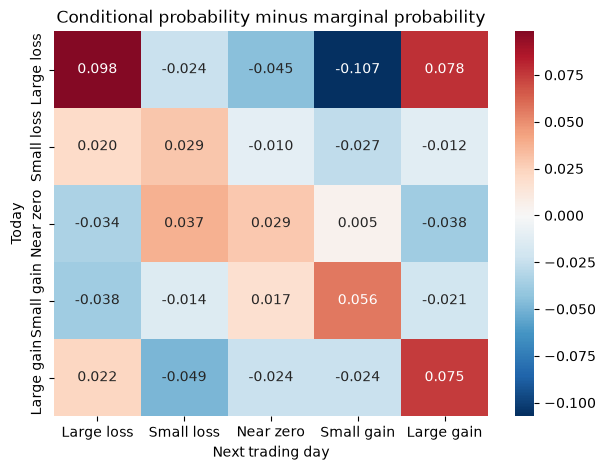

In [17]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?

<em>
I chose a threshold of .05 increase or decrease.

More likely transitions:

Large loss: to large loss or large gain
Large gain: to large gain 
Small gain: to small gain

Less likely transitions:

Large loss: to small gain



</em>

- Does knowing today's state change the forecast for tomorrow?

<em>
Yes, if there have been large losses today, you are more likely to have large losses and gains tomorrow and less likely to have small gains tomorrow.  If you have large gains, you are more likely to have large gains tomorrow. If you have small gains, you are slightly more likely to have small gains.


If you have not had large gains or losses, then knowing today's state does not strongly change the forecast for tomorrow. You are just more likely to have small gains and losses overall.

</em>

- How is this comparison different from comparing each row to a uniform PMF with probability .2?

<em>

This comparison is how much tomorrow will differ from its normal probability given today happened. The uniform distribution assumes that every condition has an equal probability; however, in this case, we have different underlying base rates across the five bins.  

 Subtracting a uniform distribution would still leave the base rate differences intact and would not isolate the effect of today's state. Using the marginal probabilities, the base rate is subtracted from the conditional probability, so only the contribution of the previous day remains.  Each value in the cell of the heatmap is the calculated amount of probability that today contributes to tomorrow.  

</em>

</div>

In [18]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby("y_t")["market_return_pct_tp1"].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


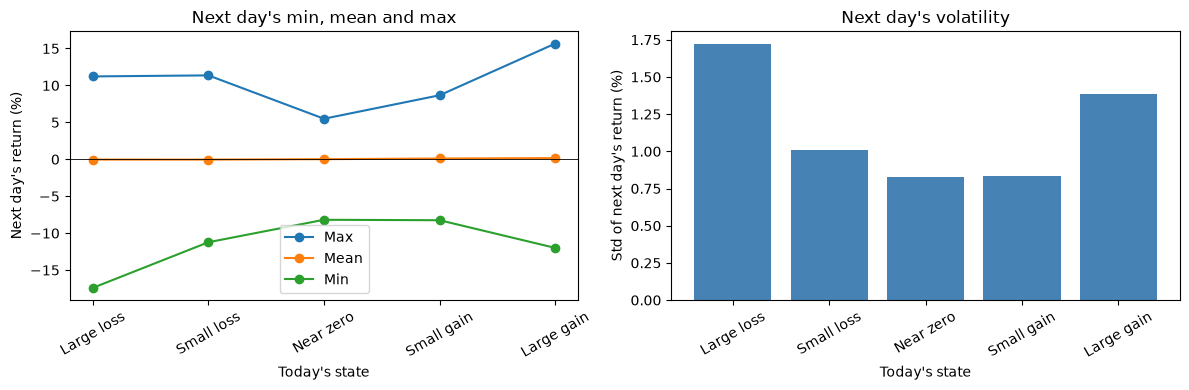

In [42]:
stats5 = df.groupby('return_bin', observed=False)['market_return_pct_tp1'].describe()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# left: next day's min, mean, and max for each of today's states
ax[0].plot(stats5.index, stats5['max'],  marker='o', label='Max')
ax[0].plot(stats5.index, stats5['mean'], marker='o', label='Mean')
ax[0].plot(stats5.index, stats5['min'],  marker='o', label='Min')
ax[0].axhline(0, color='black', linewidth=0.6)
ax[0].set(xlabel="Today's state", ylabel="Next day's return (%)",
          title="Next day's min, mean and max")
ax[0].legend()

# right: next day's standard deviation for each of today's states
ax[1].bar(stats5.index, stats5['std'], color='steelblue')
ax[1].set(xlabel="Today's state", ylabel="Std of next day's return (%)",
          title="Next day's volatility")

for a in ax:
    a.tick_params(axis='x', rotation=30)
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 

<em>

The percent returns for tomorrow for all states are approximately zero.

</em>

- How do the min and max values for tomorrow vary across states? 

<em>

For large losses, the min is -17.41 and the max is 11.22. For small losses, the min is -11.23 and the max is 11.36. For near zero, the min is -8.19 and the max is 5.49. For small gains, the min is -8.25 and the max is 8.67. For large gains, the min is -12.0 and the max is 15.67. Extreme gains and losses have larger ranges than the other three categories.


</em>

- Which states have the highest standard deviation for tomorrow's percent returns? 
<em>

The large loss and large gains have the highest standard deviation for tomorrow's percent returns.

</em> 


- Describe any patterns in the volatility you notice.

<em>

Volatility can be characterized by a large standard deviation that suggests inconsistency in the market return.  Large gains and losses show markedly larger standard deviations than the other three bins.  The range of each condition (difference between the max and min can also be used as a measure of volatility; it is somewhat similar to the standard deviation).  The range is larger for large losses and gains than for the other three conditions. These statistics suggest that large losses and gains today, predict large losses and gains the next day.  A large gain can predict a large gain, but also a large loss.  So it predicts the magnitude of the next day returns but not the direction. The degree of fluctuation and amount is higher on these days, making the prediction more uncertain.


</em>




</div>


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [19]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [ ]:
#the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

<Axes: xlabel='y_tp1', ylabel='y_t'>

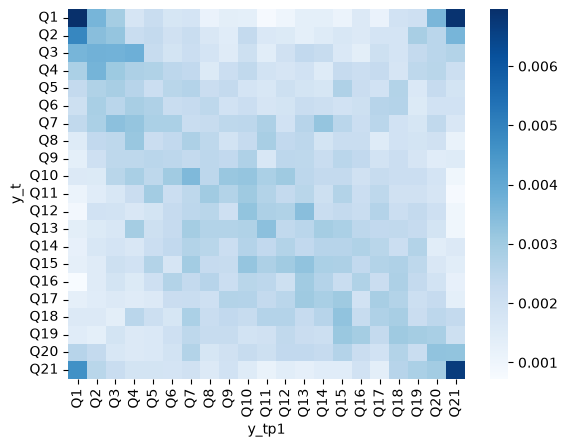

In [21]:
sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

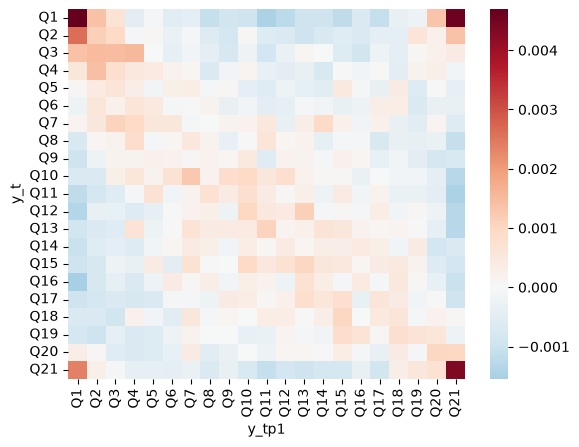

In [22]:
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

<em>

This map removes what each cell would be if every pair were equally likely.  This heatmap shows the volatility at the extremes.
It seems that the volatility is driven by the extreme ends of the large losses and gains at the largest and smallest quantile bins in the corners of the heatmap.  

The red diagonals on the heat map suggest that having one outcome one day predicts the same outcome the next.  However, the strength of this relationship increases near that diagonals corners of the graph suggesting that the extreme quantile bins are associated with a higher probability of the next day being the same as the day before.  


</em>

</div>



<Axes: xlabel='y_tp1', ylabel='y_t'>

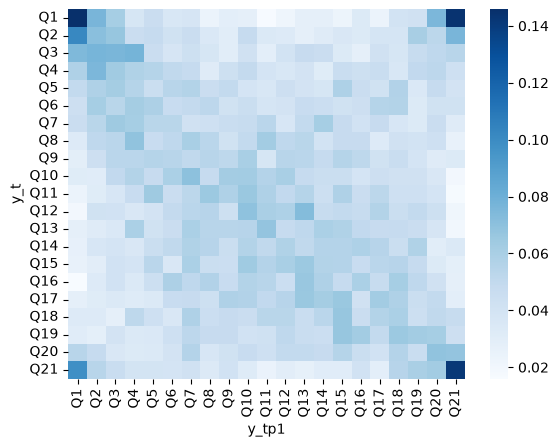

In [ ]:
 
quantile_conditional =pd.crosstab(df['y_t'], df['y_tp1'], normalize="index", margins = False)

sns.heatmap(quantile_conditional, cmap= "Blues")

<Axes: xlabel='y_tp1', ylabel='y_t'>

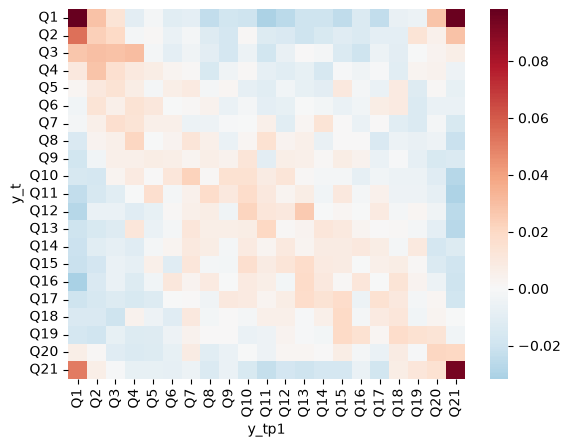

In [ ]:


# Subtract 1/21 from the PMF before plotting it, to normalize away the uniform PMF,
# and see systematic deviations from uniformly random behavior.

sns.heatmap(quantile_conditional - 1/bins, cmap= "RdBu_r", center = 0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?
<em>

This graph shows a slightly greater likelihood the next day returns being similar to the previous days returns as a result of the downward diagonal in the heatmap.

We see the strongest probabilities at the largest and smallest quantile bins at all four corners of the heatmap, meaning the same or opposite extreme gains and losses predict each other.  
</em>

</div>

In [37]:
# compute the next day's min, mean, and max conditional on each bin

quantile_conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index", margins=False)

next_day_stats= df.groupby('y_t')['market_return_pct_tp1'].describe()

next_day_stats[['min', 'mean', 'max']].rename(columns={'min': 'Next day min', 'mean': 'Next day mean', 'max': 'Next day max'})
 

,Next day min,Next day mean,Next day max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


<Axes: xlabel='y_t'>

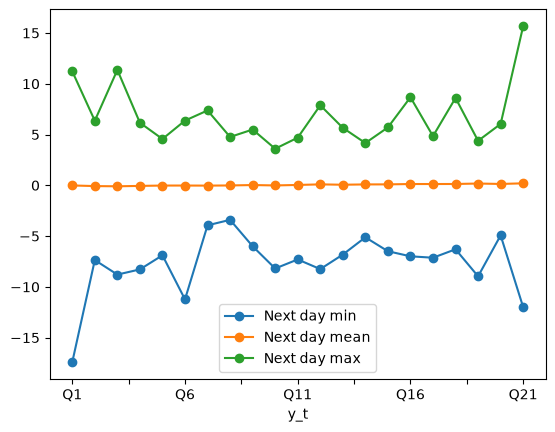

In [38]:
#plot as lines on a graph against the bins

next_day_stats[['min', 'mean', 'max']].rename(columns={'min': 'Next day min', 'mean': 'Next day mean', 'max': 'Next day max'}).plot(kind='line', marker='o')

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

<em>

The gains and losses tend to mirror each other in mins and maxes and are especially bipolar at the largest and smallest quantile bins, However, the mean is roughly zero (or slightly below), because most small and large losses are accompanied by large and small gains  which over time average out to an expectancy that is close to zero.  You are equally likely to gain or lose.

</em>

</div>

<Axes: xlabel='y_t'>

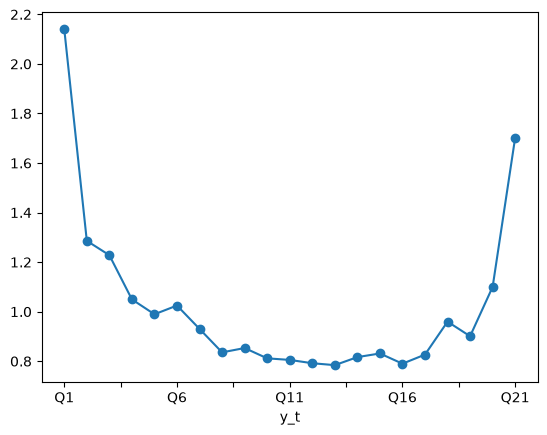

In [39]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
df.groupby('y_t')['market_return_pct_tp1'].std().rename('Next day std').plot(kind='line', marker='o')


<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?



<em>

The shape is a U, with lower variability in the middle quantile bins and higher variability at the extreme bins. The variability in the largest and smallest quantile bins are much larger than in the other quantile bins. This variability at the tails of the quantile bins reflects the massive swings from large losses and gains during periods of volatility. 

</em>


</div>

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?


<em>

The ease of predicting the market depends on whether or not one is interested in predicting the size of the change in the market, the direction of the change or both. The market has a high degree of volatility in that during volatile periods, the market swings from large gains and losses to large gains and losses.  However, the direction could either be a gain or a loss, we just know that the magnitude of the change is big.  Consequently, for those trying to play the market, if a large gain or loss has occurred, then keeping your money in the market is high risk of a large loss, but also high reward of a large gain.    


</em>

</div>